### Acknowledgement

This notebook builds on work started by Arianna Olivelli, who identified suitable CMIP6 models through the Pangeo catalog, developed the initial approach for lazy loading and concatenating historical and scenario simulations, and loaded and interpolated the input4MIPs atmospheric CO2 data. The other processing steps and their implementation were developed by me.

# CMIP6 pCO2 Diffusion Model - Get data from PANGEO

Retrieves all fields needed to train a conditional diffusion model for ocean pCO2 reconstruction:
- **Target**: `pco2_residual` (non-thermal component, Bennington et al. 2022)
- **Ocean predictors**: `tos`, `sos`, `mlotst`, `chlos`/`chl` + monthly anomalies for `tos`, `sos`, `chlos`/`chl` and `mlotst`
    - All models selected in this notebook use `chlos` as a target variable. However, one additional CMIP6 model (`UKESM1-0-LL`) has chlorophyll-a concentrations available in variable `chl` (which is depth resolved, so you need to extract data for the topmost level) and would be great to include
- **Atmospheric CO2 (predictor)**: input4MIP CO2 forcing at monthly resolution with latitudinal bands of 15 degrees

`historical` (1850–2014) and `ssp245` (2015–2100) runs are concatenated per model.

# 0. Imports & Setup

In [ ]:
import collections
import json
import os
import tempfile
import time
import warnings
from collections import defaultdict

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cftime
import cmocean
import intake
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xesmf as xe
from dask.diagnostics import ProgressBar
from natsort import natsorted
from xmip.preprocessing import (
    broadcast_lonlat,
    correct_coordinates,
    correct_lon,
    parse_lon_lat_bounds,
    promote_empty_dims,
    rename_cmip6,
    replace_x_y_nominal_lat_lon,
)

warnings.filterwarnings('ignore')

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from utils.paths import (
    CMIP6_RAW_DIR,
    INPUT4MIPS_RAW_DIR,
    CMIP6_PROCESSED_DIR,
    INPUT4MIPS_PROCESSED_DIR,
    CMIP6_FIGURES_DIR,
    ensure_project_dirs,
    assert_exists,
    print_paths
)

ensure_project_dirs()

assert_exists(INPUT4MIPS_RAW_DIR, "Input4MIPs raw data")

print(f"CMIP6 raw: {CMIP6_RAW_DIR}")
print(f"Input4MIPS raw: {INPUT4MIPS_RAW_DIR}")
print(f"CMIP6 processed: {CMIP6_PROCESSED_DIR}")
print(f"Input4MIPS processed: {INPUT4MIPS_PROCESSED_DIR}")
print(f"Figures: {CMIP6_FIGURES_DIR}")

print_paths(
    ("CMIP6 raw", CMIP6_RAW_DIR),
    ("Input4MIPS raw", INPUT4MIPS_RAW_DIR),
    ("CMIP6 processed", CMIP6_PROCESSED_DIR),
    ("Input4MIPS processed", INPUT4MIPS_PROCESSED_DIR),
    ("CMIP6 figures", CMIP6_FIGURES_DIR)
)

#### Settings

In [ ]:
# target grid for use in regridding
ds_out = xr.Dataset({
    "lat": (["lat"], np.arange(-89.5, 90, 1.0)),   # 180 points
    "lon": (["lon"], np.arange(-179.5, 180, 1.0)),  # 360 points
})

# Ocean Predictors

## Configuration

In [ ]:
# Variable groups (split by CMIP6 table) - these are the variables we will retrieve from PANGEO

# Search for models with chlos (surface chl already available)
OCEAN_VARS_CHLOS   = ["spco2", "tos", "sos", "mlotst", "chlos"]  # Omon catalog variables

# Search for models with chl (depth-resolved, need surface extraction)
# but ONLY if they don't already have chlos
OCEAN_VARS_CHL   = ["spco2", "tos", "sos", "mlotst", "chl"]

ANOMALY_VARS = ["tos", "sos", "chlos", "mlotst"]    # chlos after harmonisation

EXPERIMENTS  = ["historical", "ssp245"]

# Time boundaries
HIST_START = "1850-01"
HIST_END  = "2014-12"
SSP_START = "2015-01"
SSP_END  = "2100-12"

# Chunk sizes for lazy loading
CHUNKS = {"time": 12, "lat": 90, "lon": 90}

## Load catalog and find valid models

A model is valid if it has **all variables**, in **both experiments**, with at least one **common member**.

In [5]:
cat = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json")
df  = cat.df
print(f"Catalog entries: {len(df):,}")

Catalog entries: 514,818


In [6]:
def find_valid_models(df, ocean_vars, experiments):
    all_vars = ocean_vars
    subset = df[df["variable_id"].isin(all_vars) & df["experiment_id"].isin(experiments)]

    # Step 1: subset models/members with all variables IN EACH experiment separately
    var_counts_per_exp = (subset.groupby(["source_id", "member_id", "experiment_id"])["variable_id"].nunique().unstack("experiment_id"))

    # Must have all variables in EVERY experiment
    complete = var_counts_per_exp[(var_counts_per_exp == len(all_vars)).all(axis=1)].index  # (source_id, member_id) tuples
    complete_srcs = {idx[0] for idx in complete}

    # Step 2: both experiments present (already guaranteed above, but keep for safety)
    exp_counts = (subset[subset["source_id"].isin(complete_srcs)].groupby("source_id")["experiment_id"].nunique())
    both_exp = set(exp_counts[exp_counts == len(experiments)].index)

    # Step 3: first common member per model — only from complete (source_id, member_id) pairs
    selected = {}
    complete_dict = defaultdict(set)
    for source_id, member_id in complete:
        complete_dict[source_id].add(member_id)

    for model, members in complete_dict.items():
        if model in both_exp:
            valid = natsorted(members)
            if valid:
                selected[model] = valid[0]

    return selected

# Find models with all required variables in both experiments (historical & ssp245)
selected_chlos = find_valid_models(df, OCEAN_VARS_CHLOS, EXPERIMENTS)
selected_chl   = find_valid_models(df, OCEAN_VARS_CHL,   EXPERIMENTS) # ukesm chl search

# Keep chl-only models - exclude any that already have chlos
chl_only = {k: v for k, v in selected_chl.items() if k not in selected_chlos}

# Exclude models with near-identical ocean biogeochemistry to another selected model
# CESM2-WACCM excluded: identical POP2+MARBL ocean to CESM2, differs only in upper atmosphere
# (Danabasoglu et al. 2020 - both use POP2 + MARBL, difference is atmospheric component only)
EXCLUDE_MODELS = {"CESM2-WACCM"}
selected_chlos = {k: v for k, v in selected_chlos.items() if k not in EXCLUDE_MODELS}
chl_only       = {k: v for k, v in chl_only.items()       if k not in EXCLUDE_MODELS}

print(f"Excluded models: {EXCLUDE_MODELS}")
print(f"Models using chlos directly: {list(selected_chlos.keys())}")
print(f"Models using chl top layer:  {list(chl_only.keys())}")
print(f"Total models: {len(selected_chlos) + len(chl_only)}")

Excluded models: {'CESM2-WACCM'}
Models using chlos directly: ['CanESM5', 'CanESM5-CanOE', 'GFDL-ESM4']
Models using chl top layer:  ['CESM2', 'UKESM1-0-LL']
Total models: 5


## Search catalog

In [7]:
def build_filtered_catalog(cat, selected_members, variable_id, table_id, experiments):
    dfs = []
    for model, member in selected_members.items():
        mask = (
            (cat.df["source_id"]     == model)  &
            (cat.df["member_id"]     == member) &
            (cat.df["variable_id"].isin(variable_id)) &
            (cat.df["experiment_id"].isin(experiments)) &
            (cat.df["table_id"]      == table_id)
        )
        model_df = cat.df[mask].copy()

        # For each model, keep only the grid that has ALL variables (gn = native, gr = regridded)
        # Prefer gn, but fall back to gr if gn doesn't have all vars
        grids = model_df["grid_label"].unique()
        chosen_grid = None
        for grid in ["gn", "gr"]:  # preference order
            if grid in grids:
                vars_on_grid = set(model_df[model_df["grid_label"] == grid]["variable_id"])
                if vars_on_grid == set(variable_id):
                    chosen_grid = grid
                    break

        if chosen_grid is None:
            # No single grid has all variables — take gr as it tends to have more
            print(f"⚠️  {model}: no single grid has all variables, using gr")
            chosen_grid = "gr"

        model_df = model_df[model_df["grid_label"] == chosen_grid]
        print(f"  {model}: using grid={chosen_grid}, vars={sorted(set(model_df['variable_id']))}")
        dfs.append(model_df)

    filtered_df = pd.concat(dfs, ignore_index=True).drop_duplicates()
    return filtered_df


# Build filtered catalogs for each group
ocean_df_chlos = build_filtered_catalog(cat, selected_chlos, OCEAN_VARS_CHLOS, "Omon", EXPERIMENTS)
ocean_df_chl   = build_filtered_catalog(cat, chl_only,       OCEAN_VARS_CHL,   "Omon", EXPERIMENTS)

# Combine into one catalog dataframe
ocean_df = pd.concat([ocean_df_chlos, ocean_df_chl], ignore_index=True).drop_duplicates()

print(f"\nTotal filtered catalog entries: {len(ocean_df)}")
print(ocean_df.groupby(["source_id", "experiment_id", "grid_label"])["variable_id"].apply(set))

  CanESM5: using grid=gn, vars=['chlos', 'mlotst', 'sos', 'spco2', 'tos']


  CanESM5-CanOE: using grid=gn, vars=['chlos', 'mlotst', 'sos', 'spco2', 'tos']
  GFDL-ESM4: using grid=gr, vars=['chlos', 'mlotst', 'sos', 'spco2', 'tos']
  CESM2: using grid=gn, vars=['chl', 'mlotst', 'sos', 'spco2', 'tos']
  UKESM1-0-LL: using grid=gn, vars=['chl', 'mlotst', 'sos', 'spco2', 'tos']

Total filtered catalog entries: 50
source_id      experiment_id  grid_label
CESM2          historical     gn              {spco2, chl, mlotst, tos, sos}
               ssp245         gn              {chl, spco2, mlotst, tos, sos}
CanESM5        historical     gn            {spco2, chlos, mlotst, tos, sos}
               ssp245         gn            {spco2, chlos, mlotst, tos, sos}
CanESM5-CanOE  historical     gn            {spco2, chlos, mlotst, tos, sos}
               ssp245         gn            {spco2, chlos, mlotst, tos, sos}
GFDL-ESM4      historical     gr            {spco2, chlos, mlotst, tos, sos}
               ssp245         gr            {spco2, chlos, mlotst, tos, sos}
UKESM

### Sanity check

In [8]:
print("=== Member counts per model/experiment (should all be 1) ===")
print(ocean_df.groupby(["source_id", "experiment_id"])["member_id"].nunique().unstack())

print("\n=== Actual members selected ===")
print(ocean_df.groupby(["source_id", "experiment_id"])["member_id"].unique().unstack())

print("\n=== Variable counts per model/experiment (should all be 5) ===")
print(ocean_df.groupby(["source_id", "experiment_id"])["variable_id"].nunique().unstack())

print("=== Variables present per model/experiment ===")
print(ocean_df.groupby(["source_id", "experiment_id", "variable_id"]).size().unstack(["experiment_id", "variable_id"]).notna().astype(int))

=== Member counts per model/experiment (should all be 1) ===
experiment_id  historical  ssp245
source_id                        
CESM2                   1       1
CanESM5                 1       1
CanESM5-CanOE           1       1
GFDL-ESM4               1       1
UKESM1-0-LL             1       1

=== Actual members selected ===
experiment_id  historical      ssp245
source_id                            
CESM2          [r4i1p1f1]  [r4i1p1f1]
CanESM5        [r1i1p2f1]  [r1i1p2f1]
CanESM5-CanOE  [r1i1p2f1]  [r1i1p2f1]
GFDL-ESM4      [r1i1p1f1]  [r1i1p1f1]
UKESM1-0-LL    [r1i1p1f2]  [r1i1p1f2]

=== Variable counts per model/experiment (should all be 5) ===
experiment_id  historical  ssp245
source_id                        
CESM2                   5       5
CanESM5                 5       5
CanESM5-CanOE           5       5
GFDL-ESM4               5       5
UKESM1-0-LL             5       5
=== Variables present per model/experiment ===
experiment_id historical                      ssp245 

## Load datasets (lazy + chunked)

In [9]:
def catalog_from_filtered_df(cat, filtered_df):
    with tempfile.NamedTemporaryFile(mode="w", suffix=".csv", delete=False) as f:
        filtered_df.to_csv(f, index=False)
        tmp_csv = f.name

    esmcat_dict = cat.esmcat.dict()
    esmcat_dict["catalog_file"] = tmp_csv

    with tempfile.NamedTemporaryFile(mode="w", suffix=".json", delete=False) as f:
        json.dump(esmcat_dict, f)
        tmp_json = f.name

    new_cat = intake.open_esm_datastore(tmp_json)
    os.unlink(tmp_json)
    
    return new_cat, tmp_csv


cat_ocean_filtered, tmp_csv = catalog_from_filtered_df(cat, ocean_df)

print(f"Filtered catalog entries: {len(cat_ocean_filtered.df)}") 
print(cat_ocean_filtered.df.groupby(["source_id", "experiment_id"])["member_id"].nunique().unstack())

# dsets_ocean = cat_ocean_filtered.to_dataset_dict(zarr_kwargs={"consolidated": True}, xarray_open_kwargs={"chunks": CHUNKS})

dsets_ocean = cat_ocean_filtered.to_dataset_dict(
    zarr_kwargs={"consolidated": True,},
    storage_options={"token": "anon"}, # explicit - https://chatgpt.com/share/6a19a26d-8854-83eb-b400-9f41b47d9828
    xarray_open_kwargs={"chunks": CHUNKS,},
)

os.unlink(tmp_csv)
print("Ocean keys:", list(dsets_ocean.keys()))

Filtered catalog entries: 50
experiment_id  historical  ssp245
source_id                        
CESM2                   1       1
CanESM5                 1       1
CanESM5-CanOE           1       1
GFDL-ESM4               1       1
UKESM1-0-LL             1       1



--> The keys in the returned dictionary of datasets are constructed as follows:
	'activity_id.institution_id.source_id.experiment_id.table_id.grid_label'


<div><progress max="10" value="10"></progress> 100.00% [10/10 01:00&lt;00:00]</div>

Ocean keys: ['CMIP.NOAA-GFDL.GFDL-ESM4.historical.Omon.gr', 'ScenarioMIP.NOAA-GFDL.GFDL-ESM4.ssp245.Omon.gr', 'ScenarioMIP.MOHC.UKESM1-0-LL.ssp245.Omon.gn', 'CMIP.CCCma.CanESM5.historical.Omon.gn', 'CMIP.NCAR.CESM2.historical.Omon.gn', 'ScenarioMIP.CCCma.CanESM5.ssp245.Omon.gn', 'ScenarioMIP.CCCma.CanESM5-CanOE.ssp245.Omon.gn', 'CMIP.CCCma.CanESM5-CanOE.historical.Omon.gn', 'ScenarioMIP.NCAR.CESM2.ssp245.Omon.gn', 'CMIP.MOHC.UKESM1-0-LL.historical.Omon.gn']


## Concatenate historical + ssp245 per model

In [ ]:
def concat_experiments(dsets, model):
    """
    Find historical and ssp245 keys for a model, clean up boundary
    duplicates and NaN timesteps, then concatenate along time.
    """
    print("  Concatenating experiments...")
    
    hist_keys = [k for k in dsets if "historical" in k and f".{model}." in k]
    ssp_keys  = [k for k in dsets if "ssp245"     in k and f".{model}." in k]

    if not hist_keys or not ssp_keys:
        print(f"⚠️  Missing keys for {model}")
        return None

    if len(hist_keys) > 1 or len(ssp_keys) > 1:
        print(f"⚠️  Multiple keys for {model}: hist={hist_keys}, ssp={ssp_keys}")
        return None

    ds_hist = dsets[hist_keys[0]].squeeze(drop=True)
    ds_ssp  = dsets[ssp_keys[0]].squeeze(drop=True)

    # Historical: keep only timesteps up to and including Dec 2014 
    hist_mask = [(t.year, t.month) <= (2014, 12) for t in ds_hist.time.values]
    ds_hist   = ds_hist.isel(time=hist_mask)

    # SSP245: drop leading all-NaN timesteps (CESM2 boundary artefact)
    first_valid = 0
    for i in range(len(ds_ssp.time)):
        nan_frac = float(ds_ssp["spco2"].isel(time=i).isnull().mean())
        if nan_frac < 0.5:
            first_valid = i
            break
    if first_valid > 0:
        print(f"  {model}: dropping {first_valid} leading NaN timestep(s) from ssp245")
    ds_ssp = ds_ssp.isel(time=slice(first_valid, None))

    # SSP245: deduplicate by (year, month), keeping first valid occurrence
    seen     = set()
    ssp_mask = []
    for t in ds_ssp.time.values:
        ym = (t.year, t.month)
        if ym not in seen and 2015 <= t.year <= 2100:
            seen.add(ym)
            ssp_mask.append(True)
        else:
            ssp_mask.append(False)
    ds_ssp = ds_ssp.isel(time=ssp_mask)

    print(f"  {model}: hist={len(ds_hist.time)} + ssp={len(ds_ssp.time)} = {len(ds_hist.time) + len(ds_ssp.time)} timesteps")
    print("  Done.")

    return xr.concat([ds_hist, ds_ssp], dim="time")

## Extract surface chlorophyl

In [11]:
def extract_surface_chl_and_convert_units(ds):
    """Harmonise chlorophyll to surface chlos.
    Uses chlos directly if available, otherwise extracts topmost lev from chl.
    Converts from CMIP6 standard units kg m⁻³ to mg m⁻³ (×1e6) to match satellite data and conventions.
    Replaces negative and exact-zero values with the field's own lowest
    non-negative, non-zero value rather than clipping to exact 0.
    Found in CESM2 (negatives) and UKESM1-0-LL (a tiny number of coastal exact zeros).
    Caspian Sea masking is handled separately, post-regridding, once all
    models share a common lat/lon grid.
    """

    print("  Extracting surface chlorophyll...")

    if "chlos" in ds:
        print("  chlos already available, extracting for unit conversion.")
        surface = ds["chlos"]
        source = "chlos"
    elif "chl" in ds:
        # https://docs.xarray.dev/en/latest/api/dataarray.html
        print(f"    chl found. Dims: {ds['chl'].dims}") # ('time', 'lev', 'nlat', 'nlon')
        if "lev" in ds["chl"].dims:
            print(f"    Depth-resolved: {ds['chl'].sizes['lev']} levels. Extracting lev=0...")
            # drop by position 0 (shallowest depth lvl, drop lev scalar coordinate attached - https://docs.xarray.dev/en/stable/generated/xarray.DataArray.isel.html
            # drop array on upper/lower boundary of each lvl depth (eg lvl 0 = 0-5m), ignore error if doesnt exist - https://docs.xarray.dev/en/stable/generated/xarray.DataArray.drop_vars.html
            surface = ds["chl"].isel(lev=0, drop=True).drop_vars("lev_bounds", errors="ignore") 
            print(f"    Surface layer extracted. Shape: {surface.dims}") # ('time', 'nlat', 'nlon')
        else:
            print("    chl has no lev dimension - using directly as surface.")
            surface = ds["chl"]
        ds = ds.drop_vars("chl")
        source = "chl"
    else:
        raise ValueError("Neither 'chlos' nor 'chl' found in dataset.")

    # convert units kilogram to miligram per cubic meter
    print("    converting kg m⁻³ → mg m⁻³")
    ds["chlos"] = surface * 1e6

    chlos = ds["chlos"]
    n_neg = int((chlos < 0).sum().values)
    n_zero = int((chlos == 0).sum().values)

    if n_neg > 0 or n_zero > 0:
        pos_vals = chlos.where(chlos > 0)
        floor = float(pos_vals.min(skipna=True).values)

        if n_neg > 0:
            print(f"    Replacing {n_neg} negative chlos values with floor={floor:.6g} mg m-3")
        if n_zero > 0:
            print(f"    Replacing {n_zero} exact-zero chlos values with floor={floor:.6g} mg m-3")

        mask_valid = chlos.notnull()
        chlos = chlos.where(chlos > 0, floor).where(mask_valid)
        ds["chlos"] = chlos
    else:
        floor = None

    ds["chlos"].attrs = {
        "long_name": "Surface chlorophyll-a",
        "units": "mg m-3",
        "units_note": (
            f"converted from CMIP6 kg m-3 x 1e6; negative/zero values replaced "
            f"with lowest non-negative, non-zero value (floor={floor:.6g})"
            if floor is not None
            else "converted from CMIP6 kg m-3 x 1e6"
        ),
        "source_var": source,
    }

    print("  Done.")

    return ds

# test extract_surface_chl_and_convert_units on CESM2
test_model = list(chl_only.keys())[0]  # CESM2
test_member = chl_only[test_model]
print(f"Testing extract_surface_chl_and_convert_units on {test_model} ({test_member})...")

test_ds = concat_experiments(dsets_ocean, test_model)
print(f"  Before: vars = {list(test_ds.data_vars)}")
print(f"  chl dims: {test_ds['chl'].dims}")
print(f"  chl shape: {dict(test_ds['chl'].sizes)}")

test_ds = extract_surface_chl_and_convert_units(test_ds)
print(f"  After: vars = {list(test_ds.data_vars)}")
assert "chlos" in test_ds, "chlos not created!"
assert "chl" not in test_ds, "chl not removed!"
print(f"  chlos dims: {test_ds['chlos'].dims}")
print(f"  chlos units: {test_ds['chlos'].attrs.get('units')}")
print(f"  source_var: {test_ds['chlos'].attrs.get('source_var')}")

del test_ds  # rmv from memory

Testing extract_surface_chl_and_convert_units on CESM2 (r4i1p1f1)...
  Concatenating experiments...


  CESM2: dropping 1 leading NaN timestep(s) from ssp245
  CESM2: hist=1980 + ssp=1032 = 3012 timesteps
  Done.


  Before: vars = ['tos', 'spco2', 'mlotst', 'sos', 'chl']
  chl dims: ('time', 'lev', 'nlat', 'nlon')
  chl shape: {'time': 3012, 'lev': 15, 'nlat': 384, 'nlon': 320}
  Extracting surface chlorophyll...
    chl found. Dims: ('time', 'lev', 'nlat', 'nlon')
    Depth-resolved: 15 levels. Extracting lev=0...
    Surface layer extracted. Shape: ('time', 'nlat', 'nlon')
    converting kg m⁻³ → mg m⁻³


    Replacing 24662 negative chlos values with floor=2.19261e-08 mg m-3
  Done.
  After: vars = ['tos', 'spco2', 'mlotst', 'sos', 'chlos']
  chlos dims: ('time', 'nlat', 'nlon')
  chlos units: mg m-3
  source_var: chl


In [12]:
CASPIAN_BOUNDS = {'lat_min': 37.0, 'lat_max': 49.0, 'lon_min': 46.0, 'lon_max': 55.0}


def mask_caspian_sea(ds, var="chlos", bounds=CASPIAN_BOUNDS):
    """Mask the Caspian Sea to NaN. It is a lake, not part of the ocean
    reconstruction domain, but shows up in CMIP6 ocean output (including
    UKESM1-0-LL, which has real non-zero values there that we don't want)."""

    lat = ds["lat"]
    lon = ds["lon"]

    caspian_mask = (
        (lat >= bounds["lat_min"]) & (lat <= bounds["lat_max"]) &
        (lon >= bounds["lon_min"]) & (lon <= bounds["lon_max"])
    )

    n_caspian = int(caspian_mask.sum())
    if n_caspian > 0:
        print(f"    Masking {n_caspian} Caspian Sea cells to NaN")
        ds[var] = ds[var].where(~caspian_mask)

    return ds

## Feature engineering

### Convert `spco2` from Pa to µatm

In [ ]:
def convert_spco2_to_uatm(ds):
    print("  Converting spco2 to µatm...")
    
    if ds["spco2"].attrs.get("units") == "Pa":
        ds["spco2"] = ds["spco2"] * 9.86923
        ds["spco2"].attrs["units"] = "µatm"
    else:
        print("  spco2 units already in µatm, no conversion needed.")

    print("  Done.")

    return ds

### Compute pCO2 residual (training target)

Decomposes `spco2` into thermal and non-thermal components following Bennington et al. (2022):

$$\text{pCO2}_{\text{thermal}} = \overline{\text{pCO2}} \cdot \exp(0.0413 \cdot (\text{SST} - \overline{\text{SST}}))$$

$$\underbrace{\text{pCO2}_{\text{residual}}}_{\text{target}} = \text{pCO2} - \text{pCO2}_{\text{thermal}}$$

In [ ]:
def compute_pco2_residual(ds):
    print("  Computing residual pCO2...")
    
    # pco2_mean = ds["spco2"].mean(dim="time")
    # sst_mean  = ds["tos"].mean(dim="time")
    # pco2_T    = pco2_mean * np.exp(0.0423 * (ds["tos"] - sst_mean))

    # correct
    pco2_clim = ds["spco2"].groupby("time.month").mean("time")
    sst_clim = ds["tos"].groupby("time.month").mean("time")
    sst_anomaly = ds["tos"].groupby("time.month") - sst_clim

    pco2_T = pco2_clim.sel(month=ds.time.dt.month) * np.exp(0.0423 * sst_anomaly)


    ds["pco2_thermal"]  = pco2_T
    ds["pco2_residual"] = ds["spco2"] - pco2_T

    ds["pco2_thermal"].attrs  = {"long_name": "Thermal pCO2 component",    "units": "µatm"}
    ds["pco2_residual"].attrs = {"long_name": "Non-thermal pCO2 residual", "units": "µatm"}

    print("  Done.")

    return ds

### Compute monthly anomalies for ocean predictors

In [ ]:
ANOMALY_VARS = ["tos", "sos", "chlos", "mlotst"]

def add_monthly_anomalies(ds, variables):
    print(f"  Computing monthly anomalies for variables: {variables}...")

    for var in variables:
        clim = ds[var].groupby("time.month").mean(dim="time")
        ds[f"{var}_anom"] = ds[var].groupby("time.month") - clim
        ds[f"{var}_anom"].attrs = {
            "long_name": f"{var} monthly anomaly",
            "units": ds[var].attrs.get("units", ""),
        }

    print("  Done.")

    return ds

## Re-gridding models to common grid

In [16]:
def xmip_wrapper(ds):
    ds = ds.copy()
    
    ds = rename_cmip6(ds)
    ds = promote_empty_dims(ds)
    ds = broadcast_lonlat(ds)
    ds = replace_x_y_nominal_lat_lon(ds)
    ds = correct_lon(ds)
    ds = correct_coordinates(ds)
    ds = parse_lon_lat_bounds(ds)

    return ds

In [17]:
def standardize_and_regrid(ds, ds_out, regrid_vars, model):
    """Standardise CMIP6 coordinates with xmip, regrid to target 1°×1° grid"""
    print("  Standardising and regridding...")

    ds_std = xmip_wrapper(ds)
    regridder = xe.Regridder(
        ds_std, ds_out, "bilinear",
        unmapped_to_nan=True, # https://share.google/aimode/KggOHJmaZlj612lsU, https://xesmf.readthedocs.io/en/latest/notebooks/Curvilinear_grid.html
        periodic=True,
        ignore_degenerate=True,
    )
    ds_regridded = regridder(ds_std[regrid_vars])

    return ds_regridded

## Full processing run

In [ ]:
all_members     = {**selected_chlos, **chl_only}
chl_only_models = set(chl_only.keys())
regridded       = {}

ds_out = xr.Dataset({
    "lat": (["lat"], np.arange(-89.5, 90, 1.0)),
    "lon": (["lon"], np.arange(-179.5, 180, 1.0)),
})

REGRID_VARS = [
    "spco2", "tos", "sos", "mlotst", "chlos",
    "pco2_thermal", "pco2_residual",
    "tos_anom", "sos_anom", "chlos_anom", "mlotst_anom",
]

for model in all_members:
    out_path = os.path.join(CMIP6_PROCESSED_DIR, f"{model}.zarr") 
    if os.path.exists(out_path):
        print(f"  {model} already saved, skipping.")
        continue
    start = time.time()
    print(f"Processing {model}...")

    ds = concat_experiments(dsets_ocean, model)
    ds = extract_surface_chl_and_convert_units(ds)
    ds = convert_spco2_to_uatm(ds)
    ds = compute_pco2_residual(ds)
    ds = add_monthly_anomalies(ds, ANOMALY_VARS)
    regridded[model] = standardize_and_regrid(ds, ds_out, REGRID_VARS, model)
    regridded[model] = mask_caspian_sea(regridded[model], var="chlos")

    SAVE = True  # Set to False to skip saving

    if SAVE:
        print(f"  Saving {model} to {out_path}...")
        # rechunk to uniform sizes before saving
        regridded[model] = regridded[model].chunk({"time": 12, "lat": 180, "lon": 360})
        with ProgressBar():
            regridded[model].to_zarr(out_path, mode="w", zarr_format=2) # triggers dask compute
        print(f"  Done: saved to {out_path} with dims: {dict(regridded[model].dims)}")
    else:
        print("  Done: lazy, not saved")
    
    end = time.time()
    elapsed = end - start
    print(f"  {model} completed in {elapsed/60:.1f} min")

  CanESM5 already saved, skipping.
  CanESM5-CanOE already saved, skipping.
  GFDL-ESM4 already saved, skipping.
  CESM2 already saved, skipping.
  UKESM1-0-LL already saved, skipping.


In [ ]:
# load from saved zarrs instead of recomputing from PANGEO
regridded_local = {}
for model in all_members:
    model_path = os.path.join(CMIP6_PROCESSED_DIR, f"{model}.zarr")
    if os.path.exists(model_path):
        regridded_local[model] = xr.open_zarr(model_path)
        print(f"Loaded {model} from zarr")
    else:
        print(f"  {model} not found at {model_path} - skipping.")

print("\nModels in regridded_local:", list(regridded_local.keys()))

Loaded CanESM5 from zarr
Loaded CanESM5-CanOE from zarr


Loaded GFDL-ESM4 from zarr
Loaded CESM2 from zarr
Loaded UKESM1-0-LL from zarr

Models in regridded_local: ['CanESM5', 'CanESM5-CanOE', 'GFDL-ESM4', 'CESM2', 'UKESM1-0-LL']


## Visualisations

### 1. CMIP6 inter-model variability - global mean pCO2 residual over time

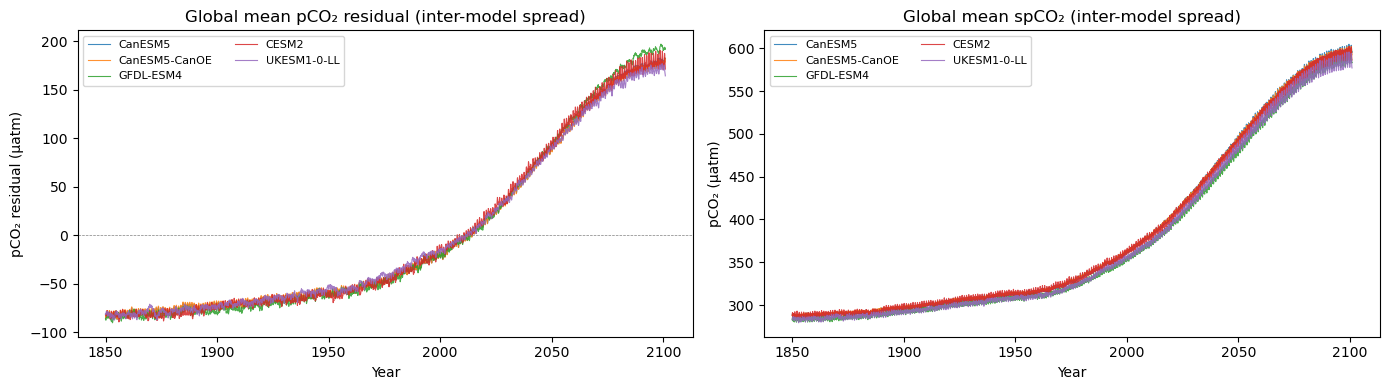

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = plt.cm.tab10.colors

for i, (model, ds) in enumerate(regridded_local.items()):
    weights = np.cos(np.deg2rad(ds["lat"]))

    # global area-weighted mean pCO2 residual over time
    residual_mean = (
        ds["pco2_residual"]
        .where(~np.isnan(ds["pco2_residual"]))
        .weighted(weights)
        .mean(dim=["lat", "lon"])
        .compute()
    )
    times = [t.year + (t.month - 1) / 12 for t in ds.time.values]
    axes[0].plot(times, residual_mean.values, label=model, color=colors[i], lw=0.8, alpha=0.85)

    # global area-weighted mean spco2 for absolute level context
    spco2_mean = (
        ds["spco2"]
        .where(~np.isnan(ds["spco2"]))
        .weighted(weights)
        .mean(dim=["lat", "lon"])
        .compute()
    )
    axes[1].plot(times, spco2_mean.values, label=model, color=colors[i], lw=0.8, alpha=0.85)

axes[0].set_title("Global mean pCO₂ residual (inter-model spread)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("pCO₂ residual (µatm)")
axes[0].legend(fontsize=8, ncol=2)
axes[0].axhline(0, color="gray", lw=0.5, linestyle="--")

axes[1].set_title("Global mean spCO₂ (inter-model spread)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("pCO₂ (µatm)")
axes[1].legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.savefig(f"{CMIP6_FIGURES_DIR}/cmip6_intermodel_variability.png", dpi=150, bbox_inches="tight")
plt.show()

### 2. Spatial map of time-mean pCO2 residual per model

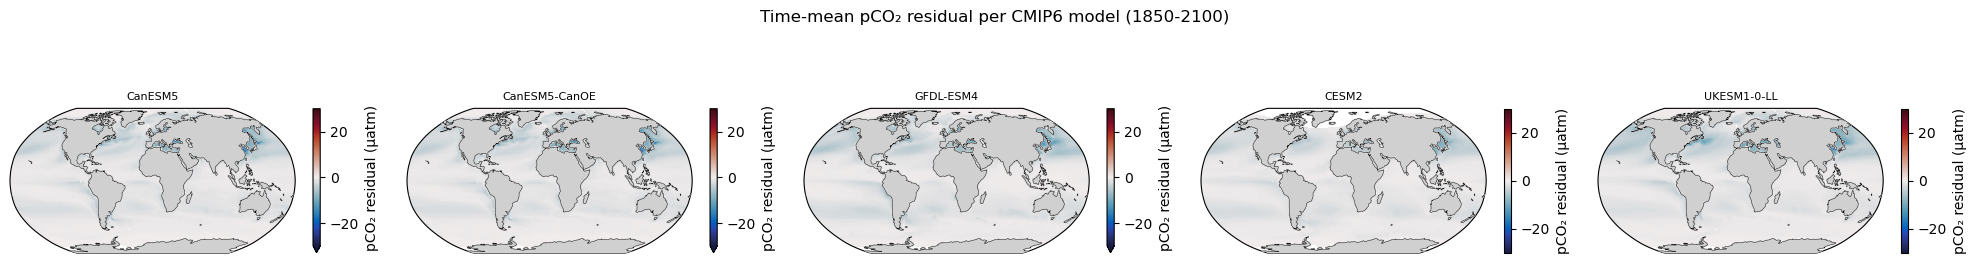

In [ ]:
n_models = len(regridded_local)
fig, axes = plt.subplots(1, n_models, subplot_kw={"projection": ccrs.Robinson()}, figsize=(4 * n_models, 3))

for ax, (model, ds) in zip(axes, regridded_local.items()):
    residual_mean = ds["pco2_residual"].mean(dim="time").compute()
    residual_mean.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmocean.cm.balance,
        vmin=-30, vmax=30,
        add_colorbar=True,
        cbar_kwargs={"label": "pCO₂ residual (µatm)", "shrink": 0.6}
    )
    ax.add_feature(cfeature.LAND, color="#d0d0d0", zorder=3)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.3, zorder=4)
    ax.set_title(model, fontsize=8)

plt.suptitle("Time-mean pCO₂ residual per CMIP6 model (1850-2100)", y=1.02)
plt.tight_layout()
plt.savefig(f"{CMIP6_FIGURES_DIR}/cmip6_residual_spatial_mean.png", dpi=150, bbox_inches="tight")
plt.show()

### 3. Seasonal cycle of pCO2 residual - inter-model spread

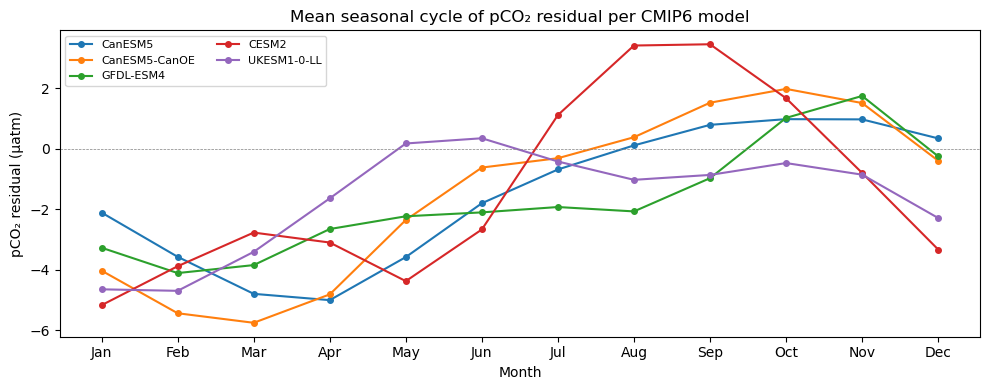

In [ ]:
# how well does each model capture seasonality

fig, ax = plt.subplots(figsize=(10, 4))
month_labels = ["Jan","Feb","Mar","Apr","May","Jun", "Jul","Aug","Sep","Oct","Nov","Dec"]

for i, (model, ds) in enumerate(regridded_local.items()):
    weights = np.cos(np.deg2rad(ds["lat"]))
    
    # global weighted mean per month
    seasonal = (
        ds["pco2_residual"]
        .where(~np.isnan(ds["pco2_residual"]))
        .weighted(weights)
        .mean(dim=["lat", "lon"])
        .groupby("time.month")
        .mean()
        .compute()
    )
    ax.plot(np.arange(1, 13), seasonal.values,
            label=model, color=colors[i], lw=1.5, marker="o", ms=4)

ax.set_xticks(np.arange(1, 13))
ax.set_xticklabels(month_labels)
ax.set_xlabel("Month")
ax.set_ylabel("pCO₂ residual (µatm)")
ax.set_title("Mean seasonal cycle of pCO₂ residual per CMIP6 model")
ax.axhline(0, color="gray", lw=0.5, linestyle="--")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(f"{CMIP6_FIGURES_DIR}/cmip6_residual_seasonal_cycle.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Inter-model spread as ensemble mean ± 1σ shading

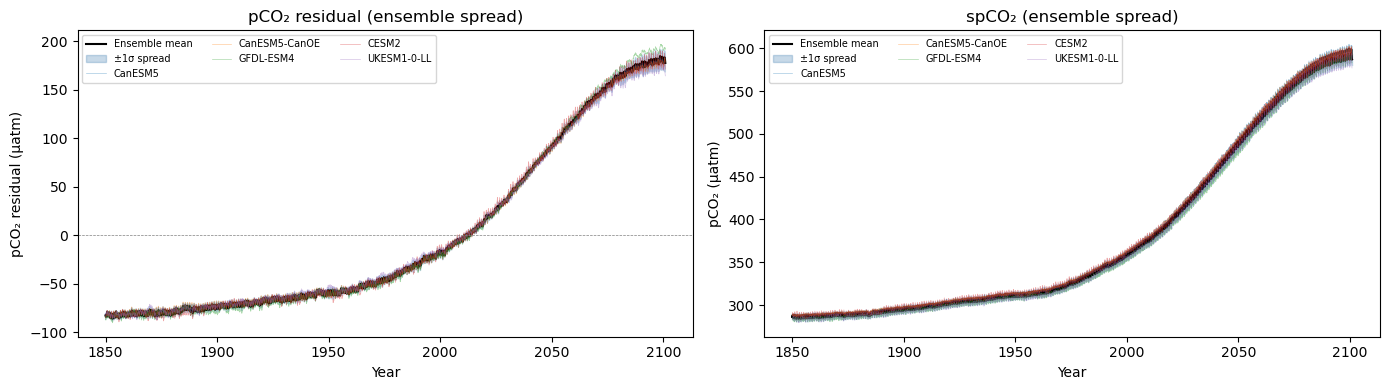

In [ ]:
# Cleaner version of Plot 1, shows where models agree vs disagree

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

residual_all = []
spco2_all = []
times_ref = None

for model, ds in regridded_local.items():
    weights = np.cos(np.deg2rad(ds["lat"]))
    
    r = (ds["pco2_residual"]
         .where(~np.isnan(ds["pco2_residual"]))
         .weighted(weights)
         .mean(dim=["lat", "lon"])
         .compute().values)
    
    s = (ds["spco2"]
         .where(~np.isnan(ds["spco2"]))
         .weighted(weights)
         .mean(dim=["lat", "lon"])
         .compute().values)
    
    residual_all.append(r)
    spco2_all.append(s)
    
    if times_ref is None:
        times_ref = [t.year + (t.month - 1) / 12 for t in ds.time.values]

residual_all = np.array(residual_all)  # shape: (n_models, n_time)
spco2_all    = np.array(spco2_all)

for data, ax, title, ylabel in [
    (residual_all, axes[0], "pCO₂ residual (ensemble spread)", "pCO₂ residual (µatm)"),
    (spco2_all,    axes[1], "spCO₂ (ensemble spread)",         "pCO₂ (µatm)")
]:
    mean = data.mean(axis=0)
    std  = data.std(axis=0)
    
    ax.plot(times_ref, mean, color="black", lw=1.5, label="Ensemble mean")
    ax.fill_between(times_ref, mean - std, mean + std,
                    alpha=0.3, color="steelblue", label="±1σ spread")
    
    # plot individual models faintly
    for i, (model, row) in enumerate(zip(regridded_local.keys(), data)):
        ax.plot(times_ref, row, color=colors[i], lw=0.5, alpha=0.4, label=model)
    
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=7, ncol=3)
    if ax == axes[0]:
        ax.axhline(0, color="gray", lw=0.5, linestyle="--")

plt.tight_layout()
plt.savefig(f"{CMIP6_FIGURES_DIR}/cmip6_ensemble_spread.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Covariate distributions - histograms per model

It seems like the two CanESM5 models have the exact same number of 0 valued cells, but we cannot clearly see this from the chlorophyll. We log scale to see if its density plotting issue with relative to the distribution of values in each model.

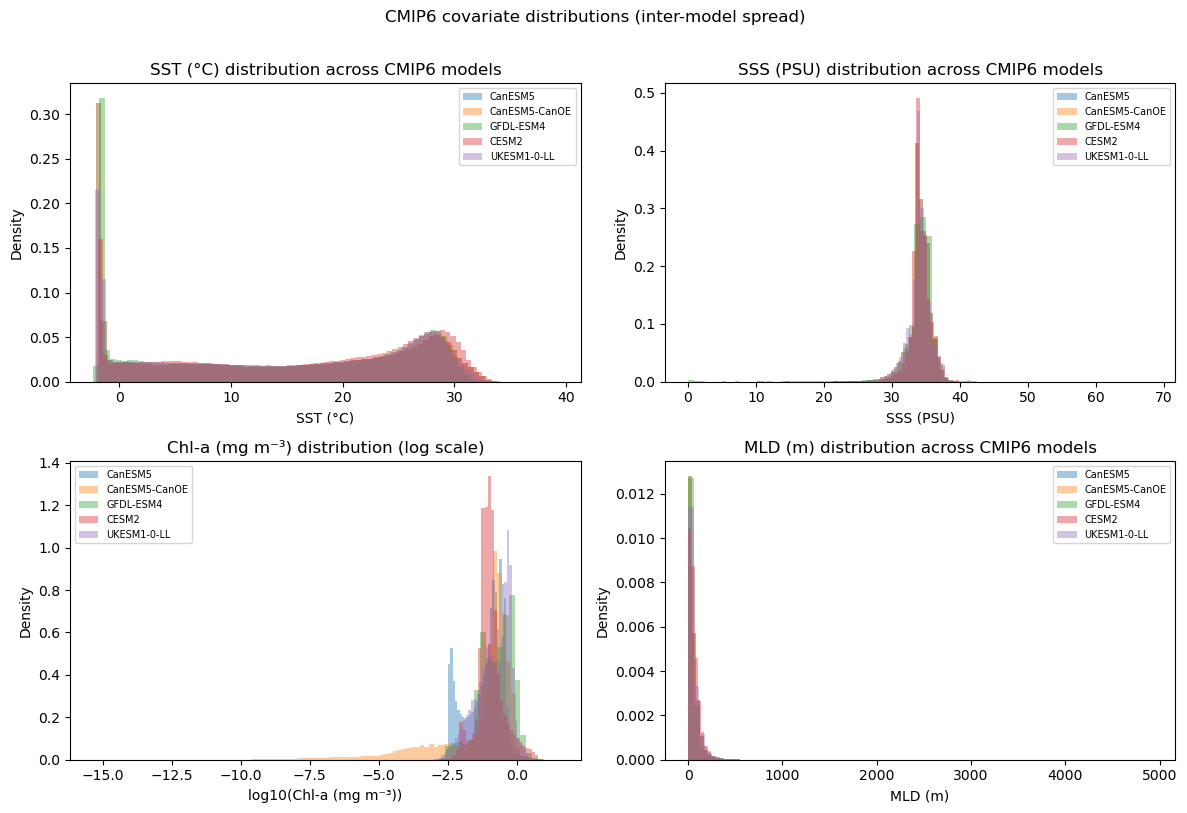

In [ ]:
# Motivates why inter-model spread helps generalise to satellite data

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
var_labels = {
    "tos":    "SST (°C)",
    "sos":    "SSS (PSU)",
    "chlos":  "Chl-a (mg m⁻³)",
    "mlotst": "MLD (m)"
}

for ax, (var, label) in zip(axes.flatten(), var_labels.items()):
    for i, (model, ds) in enumerate(regridded_local.items()):
        vals = ds[var].values.flatten()
        vals = vals[~np.isnan(vals)]

        if var == "chlos":
            valid_log = vals[vals > 0]  # log undefined for 0 and negative
            n_dropped = len(vals) - len(valid_log)
            if n_dropped > 0:
                print(f"    dropped {n_dropped} non-positive values for log plot")
            ax.hist(np.log10(valid_log), bins=80, alpha=0.4, color=colors[i],
                    label=model, density=True)
        else:
            ax.hist(vals, bins=80, alpha=0.4, color=colors[i],
                    label=model, density=True)
            
        # ax.hist(vals, bins=80, alpha=0.4, color=colors[i],
        #         label=model, density=True)
        
    if var == "chlos":
        ax.set_xlabel(f"log10({label})")
        ax.set_title(f"{label} distribution (log scale)")
    else:
        ax.set_xlabel(label)
        ax.set_title(f"{label} distribution across CMIP6 models")

    # ax.set_xlabel(label)
    ax.set_ylabel("Density")
    # ax.set_title(f"{label} distribution across CMIP6 models")
    ax.legend(fontsize=7)

plt.suptitle("CMIP6 covariate distributions (inter-model spread)", y=1.01)
plt.tight_layout()
plt.savefig(f"{CMIP6_FIGURES_DIR}/cmip6_covariate_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

There's a big spike at 0 chlorophyll levels for CanESM5-CanOE. Is this correct or is there an issue (e.g., some should actually be NaNs)?

In [25]:
## Check zero/NaN counts per model for chlos
print("Chlorophyll stats per model\n")

for model, ds in regridded_local.items():
    chl = ds["chlos"].values  # .values for xarray -> numpy array
    n_total = chl.size

    n_nan   = int(np.isnan(chl).sum())
    n_zero  = int((chl == 0).sum())
    n_neg   = int((chl < 0).sum())

    valid = chl[~np.isnan(chl)]
    n_valid = valid.size - n_neg - n_zero

    print(f"{model}:")
    print(f"  Total cells:  {n_total}")
    print(f"  NaN count:    {n_nan} ({100*n_nan/n_total:.1f}%)")
    print(f"  Zero count:   {n_zero} ({100*n_zero/n_total:.1f}%)")
    print(f"  Negative count:   {n_neg} ({100*n_neg/n_total:.1f}%)")
    print(f"  Valid (non-NaN/zero/neg): {n_valid}")
    print(f"  Stats: min={valid.min():.4g}, max={valid.max():.4g}, "
                f"p1={np.percentile(valid,1):.4g}, p50={np.percentile(valid,50):.4g}, "
                f"p99={np.percentile(valid,99):.4g}")
    if n_neg > 0 or n_zero > 0:
        print("    Lowest non-negative value:", valid[valid > 0].min()) # to see what to clip to instead of unrealistic exact 0
    print()

Chlorophyll stats per model



CanESM5:
  Total cells:  195177600
  NaN count:    70763928 (36.3%)
  Zero count:   0 (0.0%)
  Negative count:   0 (0.0%)
  Valid (non-NaN/zero/neg): 124413672


  Stats: min=5.395e-06, max=30.05, p1=0.003567, p50=0.1136, p99=1.056



CanESM5-CanOE:
  Total cells:  195177600
  NaN count:    70763928 (36.3%)
  Zero count:   0 (0.0%)
  Negative count:   0 (0.0%)
  Valid (non-NaN/zero/neg): 124413672


  Stats: min=1.177e-13, max=1.946, p1=4.234e-08, p50=0.1577, p99=0.9009



...

  Stats: min=4.581e-16, max=24.19, p1=0.003527, p50=0.2228, p99=2.077



CESM2:
  Total cells:  195177600
  NaN count:    87610044 (44.9%)
  Zero count:   0 (0.0%)
  Negative count:   0 (0.0%)
  Valid (non-NaN/zero/neg): 107567556


  Stats: min=2.193e-08, max=28.33, p1=0.008242, p50=0.09903, p99=2.989



UKESM1-0-LL:
  Total cells:  195177600
  NaN count:    70794048 (36.3%)
  Zero count:   0 (0.0%)
  Negative count:   0 (0.0%)
  Valid (non-NaN/zero/neg): 124383552


  Stats: min=1.304e-07, max=10.32, p1=0.003345, p50=0.1849, p99=1.628



In [26]:
# check where the zeros are - same locations both models?
canesm5_zero_mask = (regridded_local["CanESM5"]["chlos"].values == 0)
canoe_zero_mask   = (regridded_local["CanESM5-CanOE"]["chlos"].values == 0)

if canesm5_zero_mask.any() and canoe_zero_mask.any():
    print(f"Zero masks identical: {np.array_equal(canesm5_zero_mask, canoe_zero_mask)}")

    # check if zeros are concentrated in specific timesteps or spread across all
    zero_per_timestep = canesm5_zero_mask.sum(axis=(1,2))
    print(f"Zero count range per timestep: {zero_per_timestep.min()} to {zero_per_timestep.max()}")
    print(f"Timesteps with zero zeros: {(zero_per_timestep == 0).sum()} / {len(zero_per_timestep)}")

    # check spatial location - are they all in one place (a specific region)?
    zero_per_cell = canesm5_zero_mask.sum(axis=0)  # sum over time
    print(f"Cells that are always zero: {(zero_per_cell == canesm5_zero_mask.shape[0]).sum()}")
    print(f"Cells that are sometimes zero: {((zero_per_cell > 0) & (zero_per_cell < canesm5_zero_mask.shape[0])).sum()}")
else: 
    print("No zero values in CanESM5.")

No zero values in CanESM5.


Having 61 cells with exactly 0 across all 3012 timesteps in the two CanESM models is not a real value. It must either be a bug when regridding from their native grid to our target 1x1 using xesfm or missing data incorrectly set to 0 instead of NaNs. We first check if these values exist before our regridding processing.

In [27]:
# check if zeros exist in the ORIGINAL CanESM5 data before regridding
test_model = "CanESM5"
test_member = selected_chlos[test_model] if test_model in selected_chlos else all_members[test_model]
test_ds = concat_experiments(dsets_ocean, test_model)
test_ds = extract_surface_chl_and_convert_units(test_ds)

chl_native = test_ds["chlos"].values
n_zero_native = int((chl_native == 0).sum())
print(f"Zero count in NATIVE grid (before regridding): {n_zero_native}")
print(f"Native grid shape: {chl_native.shape}")

  Concatenating experiments...


  CanESM5: hist=1980 + ssp=1032 = 3012 timesteps
  Done.


  Extracting surface chlorophyll...
  chlos already available, extracting for unit conversion.
    converting kg m⁻³ → mg m⁻³


    Replacing 617464 exact-zero chlos values with floor=1.64519e-10 mg m-3
  Done.


Zero count in NATIVE grid (before regridding): 0
Native grid shape: (3012, 291, 360)


Turns out that regridding actually helps reduce the amount of exact 0s. We now plot the 61 persistent zero-value cells identical in both the Canadian ESMs which exist natively in the original data before our regridding.

In [ ]:
lats = regridded_local["CanESM5"]["lat"].values
lons = regridded_local["CanESM5"]["lon"].values

# zero_per_cell summed over time - cells that are zero in all 3012 timesteps
zero_per_cell = canesm5_zero_mask.sum(axis=0)
always_zero_mask = (zero_per_cell == canesm5_zero_mask.shape[0])  # True where always zero
always_zero_idx = np.where(always_zero_mask)

zero_lats = lats[always_zero_idx[0]]
zero_lons = lons[always_zero_idx[1]]

print(f"Number of persistent zero cells in CanESM5: {len(zero_lats)}")

if len(zero_lats) == 0:
    print("No persistent zero cells found — Caspian Sea masking is working as expected.")
else:
    print(f"Number of persistent zero cells: {len(zero_lats)}")
    print(f"Lat range: {zero_lats.min():.1f} to {zero_lats.max():.1f}")
    print(f"Lon range: {zero_lons.min():.1f} to {zero_lons.max():.1f}")

    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": ccrs.PlateCarree()})

    # fixed extent around the Caspian Sea region with some padding
    ax.set_extent([40, 60, 32, 52], crs=ccrs.PlateCarree())

    ax.add_feature(cfeature.LAND, color="#d0d0d0", zorder=1)
    ax.add_feature(cfeature.OCEAN, color="#e8f4f8", zorder=0)
    ax.add_feature(cfeature.LAKES, color="#cce5ff", zorder=1)  # Caspian classed as a lake?
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=2)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, linestyle=":", zorder=2)

    ax.scatter(zero_lons, zero_lats, transform=ccrs.PlateCarree(), color="red", s=60, marker="s", zorder=3, alpha=0.8, label=f"Persistent zero cells (n={len(zero_lats)})")

    ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5)
    ax.legend(loc="lower right", fontsize=9)
    ax.set_title("CanESM5/CanESM5-CanOE: 61 cells with exact-zero chlorophyll\n(identical in both models, zero in all 3012 timesteps)", fontsize=11)

    plt.tight_layout()
    plt.savefig(f"{CMIP6_FIGURES_DIR}/canesm5_persistent_zero_cells.png", dpi=150, bbox_inches="tight")
    plt.show()

    # print exact location
    print("\nExact locations of persistent zero cells:")
    for lat, lon in sorted(zip(zero_lats, zero_lons)):
        print(f"  ({lat:.1f}, {lon:.1f})")

Number of persistent zero cells in CanESM5: 0
No persistent zero cells found — Caspian Sea masking is working as expected.


It's the entirety of Caspian Sea! Should be NaNs, not exact 0s. So that's all 61 x 3012 = 183,732 exact 0 cells gone.

Let's repeat this for the tiny percentage of 0s in the UKESM1-0-LL model, just out of curiosity.

In [ ]:
# check UKESM1-0-LL zero cells location
ukesm_chl = regridded_local["UKESM1-0-LL"]["chlos"].values
ukesm_zero_mask = (ukesm_chl == 0)

lats = regridded_local["UKESM1-0-LL"]["lat"].values
lons = regridded_local["UKESM1-0-LL"]["lon"].values

zero_per_cell = ukesm_zero_mask.sum(axis=0)
always_zero_mask = (zero_per_cell == ukesm_zero_mask.shape[0])
always_zero_idx = np.where(always_zero_mask)
zero_lats = lats[always_zero_idx[0]]
zero_lons = lons[always_zero_idx[1]]

print(f"Number of persistent zero cells in UKESM1-0-LL: {len(zero_lats)}")
if len(zero_lats) > 0:
    print(f"Lat range: {zero_lats.min():.1f} to {zero_lats.max():.1f}")
    print(f"Lon range: {zero_lons.min():.1f} to {zero_lons.max():.1f}")
    print("\nExact locations:")
    for lat, lon in sorted(zip(zero_lats, zero_lons)):
        print(f"  ({lat:.1f}, {lon:.1f})")

    # auto-set extent with padding around zero cells
    pad = 10
    extent = [zero_lons.min()-pad, zero_lons.max()+pad,
              zero_lats.min()-pad, zero_lats.max()+pad]

    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": ccrs.PlateCarree()})
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, color="#d0d0d0", zorder=1)
    ax.add_feature(cfeature.OCEAN, color="#e8f4f8", zorder=0)
    ax.add_feature(cfeature.LAKES, color="#cce5ff", zorder=1)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=2)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, linestyle=":", zorder=2)

    ax.scatter(zero_lons, zero_lats, transform=ccrs.PlateCarree(), color="red", s=60, marker="s", zorder=3, alpha=0.8, label=f"Persistent zero cells (n={len(zero_lats)})")
    
    ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5)
    ax.legend(loc="lower right", fontsize=9)
    ax.set_title("UKESM1-0-LL: persistent exact-zero chlorophyll cells", fontsize=11)
    plt.tight_layout()

    plt.savefig(f"{CMIP6_FIGURES_DIR}/ukesm_persistent_zero_cells.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No cells are zero in ALL timesteps - zeros are intermittent, not persistent.") # probs
    # check how many timesteps they occur in
    sometimes_zero = (zero_per_cell > 0) & (zero_per_cell < ukesm_zero_mask.shape[0])
    print(f"Cells sometimes zero (not all timesteps): {sometimes_zero.sum()}")
    print(f"Total zero count across all timesteps: {ukesm_zero_mask.sum()}")

    # check if zeros exist in the ORIGINAL UKESM1-0-LL data before regridding
    test_model = "UKESM1-0-LL"
    test_member = selected_chlos[test_model] if test_model in selected_chlos else all_members[test_model]
    test_ds = concat_experiments(dsets_ocean, test_model)
    test_ds = extract_surface_chl_and_convert_units(test_ds)

    chl_native = test_ds["chlos"].values
    n_zero_native = int((chl_native == 0).sum())
    print(f"Zero count in NATIVE grid (before regridding): {n_zero_native}")
    print(f"Native grid shape: {chl_native.shape}")

Number of persistent zero cells in UKESM1-0-LL: 0
No cells are zero in ALL timesteps - zeros are intermittent, not persistent.
Cells sometimes zero (not all timesteps): 0
Total zero count across all timesteps: 0
  Concatenating experiments...


  UKESM1-0-LL: hist=1980 + ssp=1032 = 3012 timesteps
  Done.


  Extracting surface chlorophyll...
    chl found. Dims: ('time', 'lev', 'j', 'i')
    Depth-resolved: 75 levels. Extracting lev=0...
    Surface layer extracted. Shape: ('time', 'j', 'i')
    converting kg m⁻³ → mg m⁻³


    Replacing 683 negative chlos values with floor=1.30426e-07 mg m-3
  Done.


Zero count in NATIVE grid (before regridding): 0
Native grid shape: (3012, 330, 360)


In [ ]:
ukesm = regridded_local["UKESM1-0-LL"]
ukesm_chl = ukesm["chlos"].values
ukesm_zero_mask = (ukesm_chl == 0)

lats = ukesm["lat"].values
lons = ukesm["lon"].values
times = ukesm["time"].values

zero_per_cell = ukesm_zero_mask.sum(axis=0)

ever_zero_mask = zero_per_cell > 0
ever_zero_idx = np.where(ever_zero_mask)

zero_lats = lats[ever_zero_idx[0]]
zero_lons = lons[ever_zero_idx[1]]
zero_counts = zero_per_cell[ever_zero_idx]

print(f"Cells ever zero: {len(zero_lats)}")
print(f"Total zero occurrences: {int(ukesm_zero_mask.sum())}")


if len(zero_lats) == 0:
    print("No zero cells found in UKESM1-0-LL.")
else:
    for lat, lon, n in sorted(zip(zero_lats, zero_lons, zero_counts), key=lambda x: (-x[2], x[0], x[1])):
        print(f"({lat:.1f}, {lon:.1f}) -> {int(n)} zero timesteps")

    for i, j in zip(*ever_zero_idx):
        ts = times[ukesm_zero_mask[:, i, j]]
        print(f"\nCell ({lats[i]:.1f}, {lons[j]:.1f}) zero at {len(ts)} timesteps:")
        print("  " + ", ".join(str(t) for t in ts))

    # plot above
    chl_mean = ukesm["chlos"].mean(dim="time")

    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": ccrs.PlateCarree()})

    extent = [-20, 18, -18, 36]  # covers both clusters with padding
    ax.set_extent(extent, crs=ccrs.PlateCarree())

    chl_mean.plot(
        ax=ax, transform=ccrs.PlateCarree(),
        cmap=cmocean.cm.algae, vmin=0, vmax=2,
        cbar_kwargs={"label": "Mean chlorophyll-a (mg m-3)"}
    )

    ax.add_feature(cfeature.LAND, color="#d0d0d0", zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, linestyle=":", zorder=3)

    sizes = zero_counts * 15  # scale marker by frequency

    ax.scatter(
        zero_lons, zero_lats, transform=ccrs.PlateCarree(),
        s=sizes, facecolor="none", edgecolor="red", linewidth=1.5,
        zorder=4, label="Exact-zero cells (sized by # timesteps)"
    )

    ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5)
    ax.legend(loc="lower left", fontsize=9)
    ax.set_title("UKESM1-0-LL exact-zero chlorophyll cells over mean field", fontsize=11)

    plt.tight_layout()
    plt.savefig(f"{CMIP6_FIGURES_DIR}/ukesm_zero_cells_on_mean_field.png", dpi=150, bbox_inches="tight")
    plt.show()

Cells ever zero: 0
Total zero occurrences: 0
No zero cells found in UKESM1-0-LL.


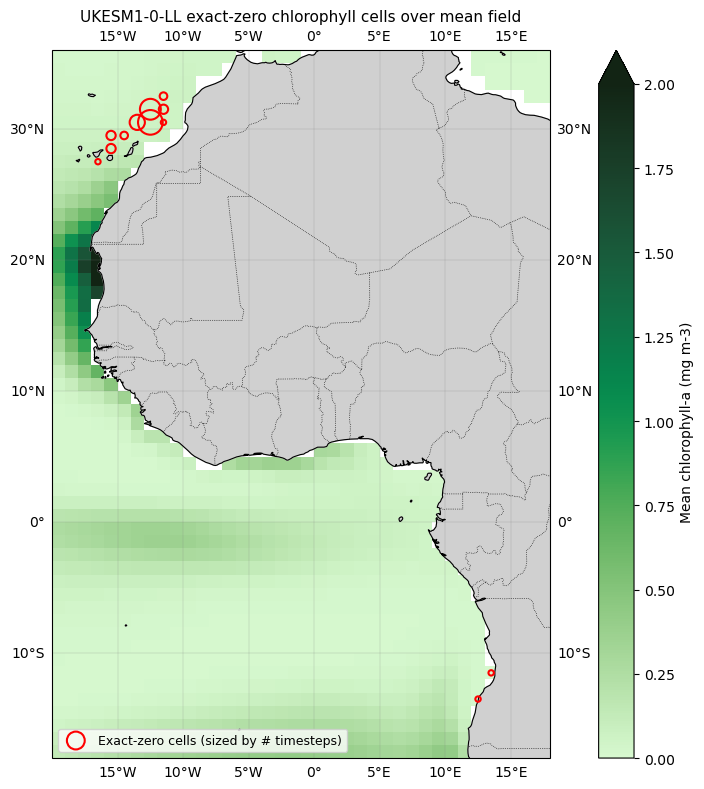

Now we look into the negative chlorophyll values in CESM2. We check whether they exist natively (before regridding) or are introduced by our xesmf bilinear regridding step

In [31]:
test_model  = "CESM2"
test_member = all_members[test_model]

# re load CESM2 from PANGEO
print(f"Loading {test_model} raw output from PANGEO...")
test_ds = concat_experiments(dsets_ocean, test_model)

# Apply ONLY chlorophyll extraction + unit conversion step
test_ds = extract_surface_chl_and_convert_units(test_ds) # no regridding yet

chl_native = test_ds["chlos"].values
print(f"\nNative grid shape: {chl_native.shape}")

n_neg_native = int((chl_native < 0).sum())
print(f"Negative count in NATIVE grid (before regridding): {n_neg_native}")

if n_neg_native > 0:
    neg_vals_native = chl_native[chl_native < 0]
    print("\nNegative values ALREADY EXIST before regridding.")
    print(f"Most negative 10 values (native): {np.sort(neg_vals_native)[:10]}")
else:
    print("\nNo negative values in native grid, probably introduced during regridding.")

# also check NATIVE grid's spatial pattern vs post-regridding equatorial Pacific found earlier
if n_neg_native > 0:
    native_lats = test_ds["lat"].values if "lat" in test_ds.coords else None
    native_lons = test_ds["lon"].values if "lon" in test_ds.coords else None
    
    if native_lats is not None and native_lats.ndim == 1:
        neg_idx = np.where(chl_native < -0.1)
        print(f"\nNative substantial negative cells (< -0.1): {(chl_native < -0.1).sum()}")
        if len(neg_idx[1]) > 0:
            print(f"Native lat range: {native_lats[neg_idx[1]].min():.1f} to {native_lats[neg_idx[1]].max():.1f}")
    else:
        print("\nNative grid has 2D lat/lon (curvilinear) - spatial check needs different indexing")
        print(f"Native lat/lon dims: {test_ds['lat'].dims if 'lat' in test_ds.coords else 'not found'}")

Loading CESM2 raw output from PANGEO...
  Concatenating experiments...


  CESM2: dropping 1 leading NaN timestep(s) from ssp245
  CESM2: hist=1980 + ssp=1032 = 3012 timesteps
  Done.


  Extracting surface chlorophyll...
    chl found. Dims: ('time', 'lev', 'nlat', 'nlon')
    Depth-resolved: 15 levels. Extracting lev=0...
    Surface layer extracted. Shape: ('time', 'nlat', 'nlon')
    converting kg m⁻³ → mg m⁻³


    Replacing 24662 negative chlos values with floor=2.19261e-08 mg m-3
  Done.



Native grid shape: (3012, 384, 320)


Negative count in NATIVE grid (before regridding): 0

No negative values in native grid, probably introduced during regridding.


In [32]:
chl = regridded_local["CESM2"]["chlos"].values
neg_vals = chl[chl < 0]

if len(neg_vals) == 0:
    print("No negative chlorophyll values in CESM2, already clipped")
else:
    print(f"Most negative 10 values: {np.sort(neg_vals)[:10]}")
    neg_idx = np.where(chl < 0)
    times_with_neg = np.unique(neg_idx[0])
    print(f"Number of distinct timesteps affected: {len(times_with_neg)}/{chl.shape[0]}")

    lats = regridded_local["CESM2"]["lat"].values
    lons = regridded_local["CESM2"]["lon"].values

    # find where the most negative values occur
    neg_mask = chl < -0.1 # filter out tiny noise
    neg_idx = np.where(neg_mask)

    if neg_mask.sum() > 0:
        neg_lats = lats[neg_idx[1]]
        neg_lons = lons[neg_idx[2]]
        
        print(f"Number of substantial negative cells (< -0.1): {neg_mask.sum()}")
        print(f"Lat range: {neg_lats.min():.1f} to {neg_lats.max():.1f}")
        print(f"Lon range: {neg_lons.min():.1f} to {neg_lons.max():.1f}")

        # joint lat/lon counts 
        location_counts = collections.Counter(zip(neg_lats.round(0), neg_lons.round(0)))
        print("Most common (lat, lon) locations:")
        for (lat, lon), count in sorted(location_counts.items(), key=lambda x: -x[1])[:15]:
            print(f"  ({lat}, {lon}): {count} occurrences")

        # which latitudes are affected
        lat_counts = collections.Counter(neg_lats.round(0))
        print("\nMost common latitudes:")
        for lat, count in sorted(lat_counts.items(), key=lambda x: -x[1])[:10]:
            print(f"  {lat}: {count} occurrences")

        # which longitudes are affected
        lon_counts = collections.Counter(neg_lons.round(0))
        print("\nMost common longitudes:")
        for lon, count in sorted(lon_counts.items(), key=lambda x: -x[1])[:10]:
            print(f"  {lon}: {count} occurrences")

        # which months are affected?
        neg_times = regridded_local["CESM2"].time.values[np.unique(neg_idx[0])]
        months_with_neg = [t.month for t in neg_times]
        month_counts = collections.Counter(months_with_neg)

        print("\nMonths affected:")
        for month, count in sorted(month_counts.items()):
            print(f"  Month {month}: {count} timesteps")

No negative chlorophyll values in CESM2, already clipped


# Atmospheric CO2

In [ ]:
## Download locally:
# https://metagrid.esgf-west.org/search/input4mips/
# 1. Source ID: UoM-CMIP-1-2-0 for historical, UoM-MESSAGE-GLOBIOM-ssp245-1-2-0 for ssp245
# 2. Variable ID: mole-fraction-of-carbon-dioxide-in-air
# 3. Grid Label: gn-15x360deg
# bash wget .sh files to downlaod & ls -lh to check size (not corrupt)

## Upload to HPC: 
# rsync -avzh --progress \
#   ~/GitHub/irp-efs25/data/raw/input4mips/ \
#   efs25@login.cx3.hpc.imperial.ac.uk:~/irp-efs25/data/raw/input4mips/

CO2_VAR = "mole_fraction_of_carbon_dioxide_in_air"

CO2_HIST_FILE = os.path.join(INPUT4MIPS_RAW_DIR, "mole-fraction-of-carbon-dioxide-in-air_input4MIPs_GHGConcentrations_CMIP_UoM-CMIP-1-2-0_gn-15x360deg_000001-201412.nc")
CO2_SSP_FILE = os.path.join(INPUT4MIPS_RAW_DIR, "mole-fraction-of-carbon-dioxide-in-air_input4MIPs_GHGConcentrations_ScenarioMIP_UoM-MESSAGE-GLOBIOM-ssp245-1-2-0_gn-15x360deg_201501-250012.nc")

CO2_SAVE_PATH = os.path.join(INPUT4MIPS_PROCESSED_DIR, "atmCO2_1850_2100_regridded.zarr")

### Load data from files

In [ ]:
def load_co2_file(path, verbose=True):
    """Load one input4MIPs CO2 file, decode time with cftime, clean duplicate
    year-month entries, fill missing months, and drop unnecessary bounds vars."""

    ds = xr.open_dataset(path, decode_times=False)

    time_decoded = cftime.num2date(
        ds["time"].values,
        units=ds["time"].attrs["units"],
        calendar="proleptic_gregorian",
        only_use_cftime_datetimes=True,
    )
    ds = ds.assign_coords(time=("time", time_decoded))

    # Snap all timestamps to month-start for clean grouping
    clean_times = [cftime.DatetimeProlepticGregorian(t.year, t.month, 1) for t in ds.time.values]
    ds = ds.assign_coords(time=("time", clean_times))

    # Average any duplicate (year, month) pairs
    ds = ds.groupby("time").mean()

    # Build complete monthly time axis
    full_times = [
        cftime.DatetimeProlepticGregorian(y, m, 1)
        for y in range(ds.time.values[0].year, ds.time.values[-1].year + 1)
        for m in range(1, 13)
    ]

    # Check for gaps
    actual = {(t.year, t.month) for t in ds.time.values}
    missing = [(t.year, t.month) for t in full_times if (t.year, t.month) not in actual]
    if missing and verbose:
        print(f"  ⚠️  {len(missing)} missing month(s) — interpolating")

    # Reindex to full time axis, then interpolate gaps
    ds = ds.reindex(time=full_times)
    ds = ds.interpolate_na(dim="time")
    
    if verbose:
        print(f"  {len(ds.time)} timesteps: {ds.time.values[0]} → {ds.time.values[-1]}")
        print(f"  Variables: {list(ds.data_vars)}")
        print(f"  Dims: {dict(ds.sizes)}")

    return ds

### Slice data to match ESM output windows

In [ ]:
def slice_co2(co2_hist, co2_ssp, hist_start_year=1850, hist_end_year=2014, ssp_start_year=2015, ssp_end_year=2100):
    """Slice historical and SSP CO2 to 1850-2100 period and concatenate """
    
    print("  Slicing CO2 to 1850-2100...")
    
    co2_hist = co2_hist.sel(time=[t for t in co2_hist.time.values if hist_start_year <= t.year <= hist_end_year])
    co2_ssp = co2_ssp.sel(time=[t for t in co2_ssp.time.values if ssp_start_year <= t.year <= ssp_end_year])
    
    co2 = xr.concat([co2_hist, co2_ssp], dim="time")

    # find missing year-month combinations - should be 0
    expected = {(y, m) for y in range(hist_start_year, ssp_end_year + 1) for m in range(1, 13)}
    actual = {(t.year, t.month) for t in co2.time.values}
    missing = sorted(expected - actual)
    print(f"  Missing month-year combinations: {len(missing)} (should be 0)")
    for ym in missing: 
        print(f"    {ym[0]}-{ym[1]:02d}")
    
    print(f"  Done: {len(co2.time)} timesteps, {co2.time.values[0]} → {co2.time.values[-1]}") # should be 3012 1850-01-01 → 2100-12-01 00:00:000
    
    return co2, co2_hist, co2_ssp

### Clean to standard dimensions

In [36]:
def standardise_co2_dims(ds, co2_var=CO2_VAR, ds_out=None, verbose=True):
    """Return a clean CO2 dataset with only (time, lat, lon) dimensions.

    Drops bound variables and collapses/removes other unused dimensions if present.
    """
    ds = ds.copy()

    drop_vars = [
        v for v in [
            "time_bnds", "lat_bnds", "lon_bnds",
            "time_bounds", "lat_bounds", "lon_bounds",
            "bounds_lat", "bounds_lon", "bounds_time",
        ]
        if v in ds.variables
    ]
    if drop_vars:
        ds = ds.drop_vars(drop_vars, errors="ignore")

    for dim in ["bnds", "bound", "nbnds", "vertices"]:
        if dim in ds.dims:
            keepers = [v for v in ds.data_vars if dim not in ds[v].dims]
            if co2_var in ds and dim in ds[co2_var].dims:
                ds[co2_var] = ds[co2_var].isel({dim: 0}, drop=True)
            ds = ds[keepers + ([co2_var] if co2_var in ds.data_vars and co2_var not in keepers else [])]

    if isinstance(ds, xr.DataArray):
        ds = ds.to_dataset(name=co2_var)

    if ds_out is not None:
        if "lat" in ds_out.coords:
            ds = ds.assign_coords(lat=ds_out["lat"])
        if "lon" in ds_out.coords and "lon" in ds[co2_var].dims:
            ds = ds.assign_coords(lon=ds_out["lon"])

    ds = ds.transpose("time", "lat", "lon", missing_dims="ignore")

    if verbose:
        print("  Standardized CO2 dims")
        print(f"  Dims: {dict(ds.sizes)}")
        print(f"  Coords: {list(ds.coords)}")

    return ds

### Regrid and save CO2 to 1×1 grid (match ESM)

In [37]:
def regrid_and_save_co2(co2_sliced, ds_out, save_path, save=False):
    """Regrid atmospheric CO2 from 12 lat bands --> full 360x180 grid.

    Step 1. interp(): 12 lat bands --> 180 lat points (1 deg resolution)
    Step 2. broadcast_like(): repeat each lat value across 360 lon points

    Optionally saves to zarr
    """
    print("  Regridding atmospheric CO2...")

    # Step 1: interpolate lat from 12 bands to 180 pts
    # fill_value="extrapolate" avoids NaN at poles where 12-band grid doesn't
    # perfectly cover -90/+90

    # CO2 forcing file has 12 lat bands of 30 deg each (-90 to +90)
    # but target grid has 180 lat points of 1 deg each (-89.5 to +89.5)
    # need interpolate missing lat points!
    # https://docs.xarray.dev/en/latest/generated/xarray.DataArray.interp.html
    co2_interp = co2_sliced.interp(
        lat=ds_out["lat"].values, # target: 180 points at 1 deg intervals -89.5. -88.5, ..., +89.5
        method="linear", # linearly between the 12 band values
        kwargs={"fill_value": "extrapolate"}, # handles edges -90 and +90 so we dont get nans at the poles (12 band grid doesnt perfectly cover these)
    )
    # result: (time=3012, lat=180) - 1 deg lat resolution, but still no lon dimension

    # Step 2: add lon dimension and broadcast uniformly
    # file has only lat bands, no lon dimension bc CO2 concentration doesnt very with longitude
    # need add dummy lonn dimension and broadcast to full 360 points to match target grid!
    co2_regridded = co2_interp.expand_dims({"lon": ds_out["lon"].values}, axis=-1) # adds a new lon dimension with our 360 target values
    co2_regridded = co2_regridded.broadcast_like(xr.Dataset({"lat": ds_out["lat"], "lon": ds_out["lon"]}))
        # xr.Dataset({"lon": ds_out["lon"], "lat": ds_out["lat"]})) 
    # broadcast to repeat the lat band co2 across all 360 lon pts ==> every cell at the same latitude gets the same co2 value
    # result: (time=3012, lat=180, lon=360) - now a full 2D global field per timestep!

    co2_regridded = standardise_co2_dims(
        co2_regridded,
        co2_var=CO2_VAR,
        ds_out=ds_out,
        verbose=True,
    )

    print(f"  Regridded dims: {dict(co2_regridded.sizes)}")
    print(f"  Period: {co2_regridded.time.values[0]} -> {co2_regridded.time.values[-1]}")

    if save:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        co2_regridded.to_zarr(save_path, mode="w", zarr_format=2)
        print(f"  Saved to {save_path}")
    else:
        print("  Done: lazy, not saved")

    return co2_regridded, co2_interp  # return interp too for plotting

### Run atmospheric CO2 processing

In [38]:
# load, slice, regrid
co2_hist = load_co2_file(CO2_HIST_FILE)
co2_ssp = load_co2_file(CO2_SSP_FILE)

co2_sliced, co2_hist_sliced, co2_ssp_sliced = slice_co2(co2_hist, co2_ssp)

co2_regridded, co2_interp = regrid_and_save_co2(co2_sliced, ds_out, CO2_SAVE_PATH, save=IS_HPC)

  24180 timesteps: 0000-01-01 00:00:00 → 2014-12-01 00:00:00
  Variables: ['time_bnds', 'lat_bnds', 'mole_fraction_of_carbon_dioxide_in_air']
  Dims: {'lat': 12, 'time': 24180, 'bound': 2}


  ⚠️  92 missing month(s) — interpolating
  5844 timesteps: 2014-01-01 00:00:00 → 2500-12-01 00:00:00
  Variables: ['lat_bnds', 'time_bnds', 'mole_fraction_of_carbon_dioxide_in_air']
  Dims: {'lat': 12, 'time': 5844, 'bnds': 2}
  Slicing CO2 to 1850-2100...
  Missing month-year combinations: 0 (should be 0)
  Done: 3012 timesteps, 1850-01-01 00:00:00 → 2100-12-01 00:00:00
  Regridding atmospheric CO2...


  Standardized CO2 dims
  Dims: {'lat': 180, 'lon': 360, 'time': 3012}
  Coords: ['time', 'lat', 'lon']
  Regridded dims: {'lat': 180, 'lon': 360, 'time': 3012}
  Period: 1850-01-01 00:00:00 -> 2100-12-01 00:00:00


  Saved to /rds/general/user/efs25/home/irp-efs25/data/processed/input4mips/atmCO2_1850_2100_regridded.zarr


### Checks

#### Extra timesteps

In [39]:
print(f"Historical timesteps: {len(co2_hist_sliced.time)}")  # expect 1980 (165 years × 12)
print(f"SSP245 timesteps:     {len(co2_ssp_sliced.time)}")   # expect 1032 (86 years × 12)

# Check first and last timestamps of each
print(f"Historical: {co2_hist_sliced.time.values[0]} → {co2_hist_sliced.time.values[-1]}")
print(f"SSP245:     {co2_ssp_sliced.time.values[0]} → {co2_ssp_sliced.time.values[-1]}")

# Check for duplicates within each file separately
for name, ds in [('historical', co2_hist_sliced), ('ssp245', co2_ssp_sliced)]:
    ym = [(t.year, t.month) for t in ds.time.values]
    dupes = [(y, m) for (y, m), count in pd.Series(ym).value_counts().items() if count > 1]
    print(f"{name} internal duplicates: {dupes}")

Historical timesteps: 1980
SSP245 timesteps:     1032
Historical: 1850-01-01 00:00:00 → 2014-12-01 00:00:00
SSP245:     2015-01-01 00:00:00 → 2100-12-01 00:00:00
historical internal duplicates: []
ssp245 internal duplicates: []


#### CO2 values over time

CO2 variable: mole_fraction_of_carbon_dioxide_in_air, units: 1.e-6


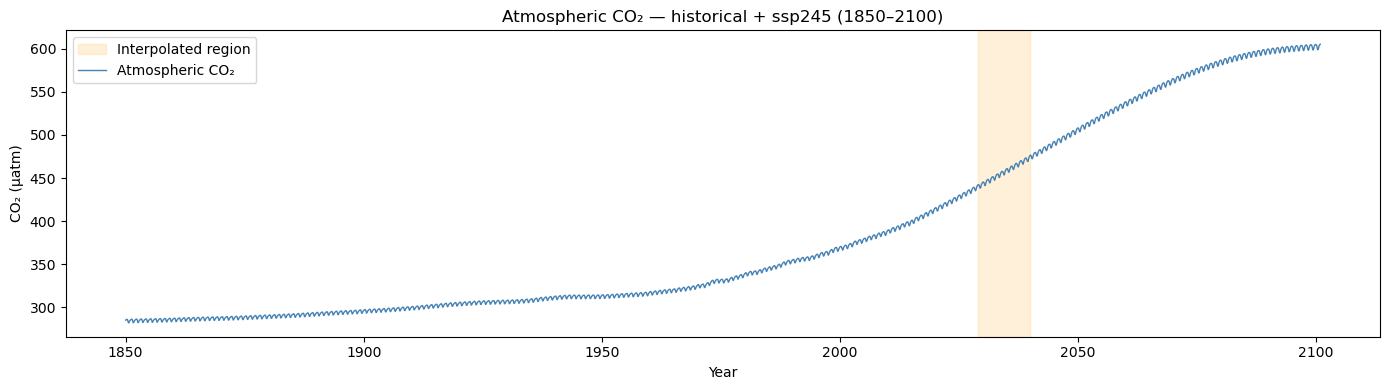

In [40]:
print(f"CO2 variable: {CO2_VAR}, units: {co2_sliced[CO2_VAR].attrs.get('units')}")

# Global mean (average over lat, weighted by cos(lat))
weights = np.cos(np.deg2rad(co2_sliced['lat'].values))
co2_mean = (co2_sliced[CO2_VAR] * weights[np.newaxis, :]).sum('lat') / weights.sum()

times = [t.year + (t.month - 1) / 12 for t in co2_sliced.time.values]

# Mark interpolated region
interp_start = 2029
interp_end   = 2040

fig, ax = plt.subplots(figsize=(14, 4))
ax.axvspan(interp_start, interp_end, color='orange', alpha=0.15, label='Interpolated region')
ax.plot(times, co2_mean.values, lw=1, color='steelblue', label='Atmospheric CO₂')
ax.set_xlabel('Year')
ax.set_ylabel('CO₂ (µatm)')
ax.set_title('Atmospheric CO₂ — historical + ssp245 (1850–2100)')
ax.legend()
plt.tight_layout()
plt.show()

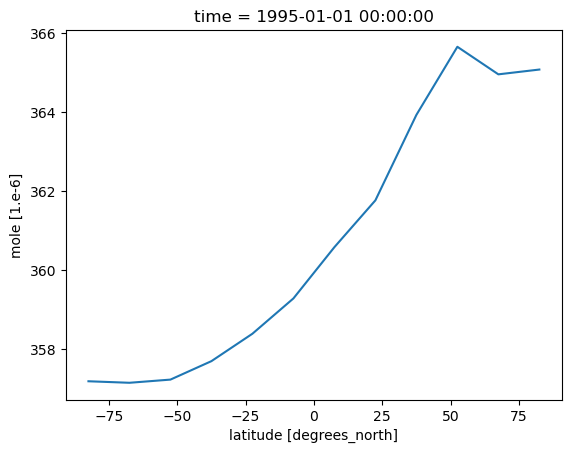

In [41]:
co2_sliced[CO2_VAR].sel(time='1995-01-01').plot()

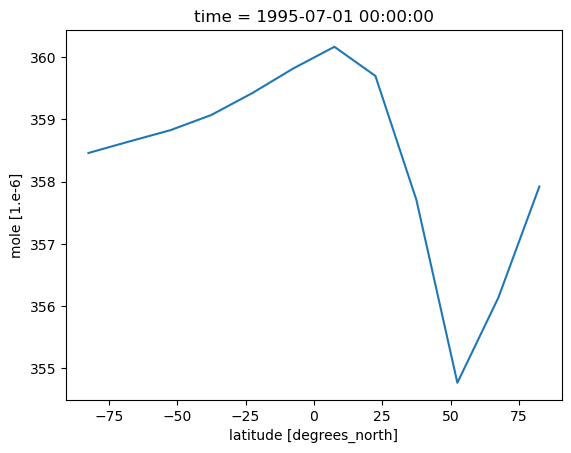

In [42]:
co2_sliced[CO2_VAR].sel(time='1995-07-01').plot()

#### Plot regrid

co2_row shape: (360,), lons shape: (360,)


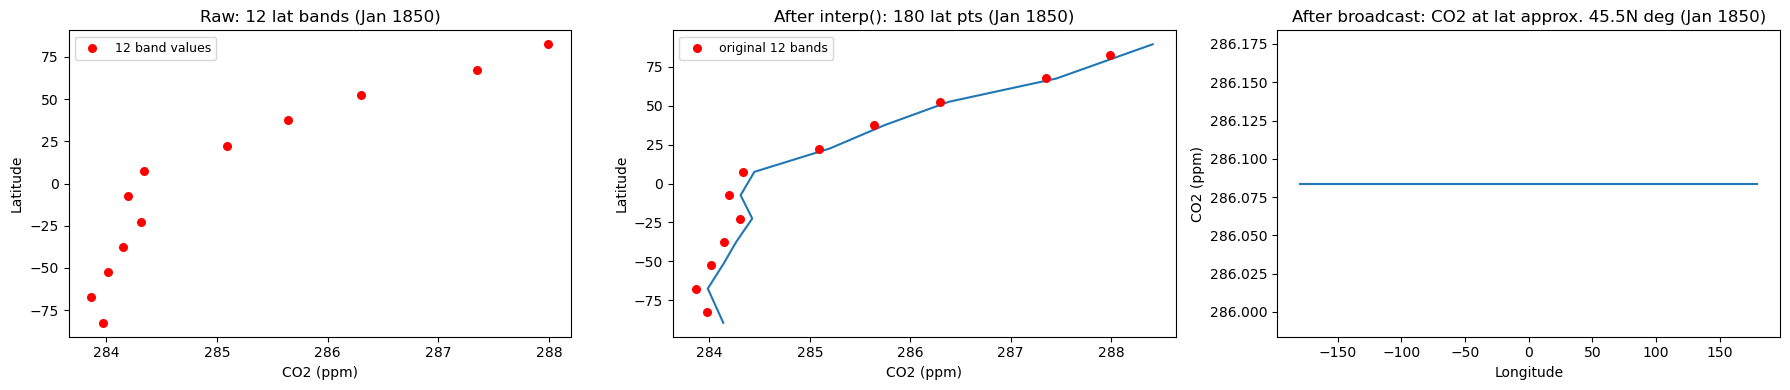

In [43]:
## before/after regridding + broadcast confirm

# load raw file just for plotting 
_co2_raw = xr.open_dataset(CO2_HIST_FILE, decode_times=False)
# raw file starts at year 0001, Jan 1850 is at index 1849*12
raw_1850_idx = 1849 * 12
raw_vals = _co2_raw[CO2_VAR].isel(time=raw_1850_idx).squeeze().values.flatten()
raw_lats = _co2_raw["lat"].values.flatten()
del _co2_raw

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. raw 12 lat bands
axes[0].scatter(raw_vals, raw_lats, color="red", s=30, zorder=5, label=f"{len(raw_lats)} band values")
axes[0].set_title(f"Raw: {len(raw_lats)} lat bands (Jan 1850)")
axes[0].set_xlabel("CO2 (ppm)")
axes[0].set_ylabel("Latitude")
axes[0].legend(fontsize=9)

# 2. after interp 180 lat pts, overlay original 12 bands
interp_vals = co2_interp[CO2_VAR].isel(time=0).squeeze().values.flatten()
interp_lats = co2_interp["lat"].values.flatten()

axes[1].plot(interp_vals, interp_lats)
axes[1].scatter(raw_vals, raw_lats, color="red", s=30, zorder=5, label=f"original {len(raw_lats)} bands")
axes[1].set_title(f"After interp(): {len(interp_lats)} lat pts (Jan 1850)")
axes[1].set_xlabel("CO2 (ppm)")
axes[1].set_ylabel("Latitude")
axes[1].legend(fontsize=9)

# 3. after broadcast, flat line confirms uniform lon
co2_slice = (co2_regridded[CO2_VAR].isel(time=0).sel(lat=45.5, method="nearest"))
# drop all non-lon dimensions
for dim in list(co2_slice.dims):
    if dim != "lon":
        co2_slice = co2_slice.isel({dim: 0}, drop=True)
co2_row = co2_slice.values.flatten()
lons = co2_regridded["lon"].values.flatten()
print(f"co2_row shape: {co2_row.shape}, lons shape: {lons.shape}")  # both (360,)

axes[2].plot(lons, co2_row)
axes[2].set_title("After broadcast: CO2 at lat approx. 45.5N deg (Jan 1850)")
axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("CO2 (ppm)")
axes[2].set_ylim(co2_row.min() - 0.1, co2_row.max() + 0.1)

plt.tight_layout()
plt.show()

flat line in plot 3 = same value across all 360 lonigtudes